# Multi-armed bandit policies

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/reinforcement-learning/01-multi-armed-bandits.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A multi-armed bandit is the smallest reinforcement-learning problem: at each decision, an agent chooses one action and observes one reward. There is no changing state and no delayed consequence. The challenge is that the reward distributions are initially unknown.

[← Return to Reinforcement learning](index.qmd)

## What we will do

This notebook uses the four-arm Gaussian bandit with which the [interactive explorer](bandit-explorer.qmd) begins. Its **New simulation** button then draws fresh arm distributions from the same Gaussian setup. We will:

1. Define the fixed but unknown reward distribution for each arm.
2. Run greedy, $\epsilon$-greedy, and upper-confidence-bound (UCB) policies on one sampled trajectory.
3. Repeat the experiment many times to compare their typical behavior.

For arm $a$, a reward follows $R \mid A=a \sim \mathcal{N}(\mu_a, \sigma_a^2)$. The correct long-run value of an arm is its mean reward $\mu_a$, but the agent must estimate it from the rewards it observes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# Each row is one action (arm) available to the agent.
# These are the interactive explorer's initial arm parameters.
ARMS = pd.DataFrame(
    {
        "arm": ["A", "B", "C", "D"],
        "mean_reward": [0.31, 0.54, 0.76, 0.43],
        "reward_std": [0.25, 0.27, 0.22, 0.26],
    }
)

ARMS

,arm,mean_reward,reward_std
0,A,0.31,0.25
1,B,0.54,0.27
2,C,0.76,0.22
3,D,0.43,0.26


## 1. The fixed reward environment

The table above is the simulator's hidden answer. The agent does **not** receive these means or standard deviations. It only chooses an arm and sees one sampled reward. Arm C has the highest mean reward, so it is the arm an agent should increasingly select after learning.

The Normal curves below show the underlying distributions. Their overlap matters: a single reward from a weaker arm can exceed a single reward from the best arm.

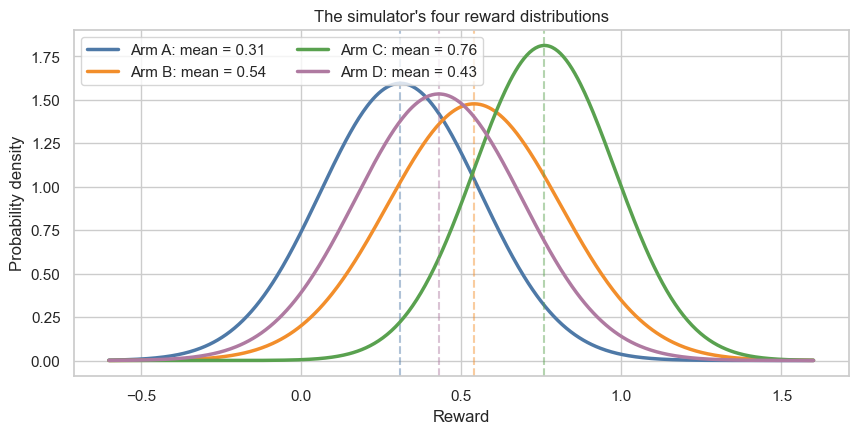

In [2]:
def normal_density(x, mean, std):
    """Evaluate a Normal probability-density function without SciPy."""
    coefficient = 1 / (std * np.sqrt(2 * np.pi))
    exponent = -0.5 * ((x - mean) / std) ** 2
    return coefficient * np.exp(exponent)

x = np.linspace(-0.6, 1.6, 500)
colors = ["#4e79a7", "#f28e2b", "#59a14f", "#af7aa1"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for arm, color in zip(ARMS.itertuples(index=False), colors):
    density = normal_density(x, arm.mean_reward, arm.reward_std)
    ax.plot(x, density, color=color, linewidth=2.5, label=f"Arm {arm.arm}: mean = {arm.mean_reward:.2f}")
    ax.axvline(arm.mean_reward, color=color, linestyle="--", alpha=0.45)

ax.set(xlabel="Reward", ylabel="Probability density", title="The simulator's four reward distributions")
ax.legend(ncol=2, frameon=True)
plt.show()

### Sampling rewards

`GaussianBandit` represents the environment. It owns a separate random-number generator for each arm, so the reward stream for one arm does not depend on which other arms the policy chose. This mirrors the explorer and makes policy comparisons easier to interpret.

In [3]:
class GaussianBandit:
    """A stationary K-armed bandit with one Gaussian reward distribution per arm."""

    def __init__(self, arm_config, seed):
        self.means = arm_config["mean_reward"].to_numpy(dtype=float)
        self.stds = arm_config["reward_std"].to_numpy(dtype=float)
        # One generator per arm keeps each arm's reward sequence independent.
        self.generators = [np.random.default_rng(seed + 7_919 * index)
                           for index in range(len(self.means))]

    def pull(self, arm):
        """Draw one reward after choosing the zero-based arm index."""
        return self.generators[arm].normal(self.means[arm], self.stds[arm])

bandit = GaussianBandit(ARMS, seed=104_729)
sample_rewards = [bandit.pull(2) for _ in range(8)]  # The agent would not know this is Arm C.
np.round(sample_rewards, 2)

array([0.88, 0.79, 0.59, 0.66, 0.68, 0.75, 0.66, 0.83])

## 2. Policies that choose an arm

Every policy maintains an estimate $Q_t(a)$ for each arm. After pulling arm $a$ and observing reward $r_t$, it uses the incremental sample-mean update:

$$
Q_{t+1}(a) = Q_t(a) + \frac{r_t - Q_t(a)}{N_{t+1}(a)}.
$$

The policies differ only in how they select the next arm:

- **Greedy:** choose the arm with the largest current estimate.
- **$\epsilon$-greedy:** with probability $\epsilon$, choose a random arm; otherwise choose greedily.
- **UCB:** choose the largest estimate plus an uncertainty bonus, $Q_t(a) + c\sqrt{\log(t+1)/N_t(a)}$.

We use the same defaults as the explorer: $\epsilon=0.20$ and $c=0.50$.

In [4]:
def random_argmax(values, rng):
    """Break ties randomly instead of always choosing the first arm."""
    candidates = np.flatnonzero(np.isclose(values, values.max()))
    return int(rng.choice(candidates))


def run_bandit_policy(policy, steps=200, epsilon=0.20, c=0.50, environment_seed=104_729, policy_seed=81_571):
    """Run one bandit policy and return its decision-by-decision history."""
    bandit = GaussianBandit(ARMS, seed=environment_seed)
    policy_rng = np.random.default_rng(policy_seed)
    k = len(ARMS)
    estimates = np.zeros(k)
    counts = np.zeros(k, dtype=int)
    total_reward = 0.0
    history = []

    for t in range(steps):
        if policy == "greedy":
            action = random_argmax(estimates, policy_rng)
            decision_type = "greedy"
        elif policy == "epsilon_greedy":
            if policy_rng.random() < epsilon:
                action = int(policy_rng.integers(k))
                decision_type = "explore"
            else:
                action = random_argmax(estimates, policy_rng)
                decision_type = "exploit"
        elif policy == "ucb":
            untried = np.flatnonzero(counts == 0)
            if len(untried):
                action = int(policy_rng.choice(untried))
            else:
                bonus = c * np.sqrt(np.log(t + 1) / counts)
                action = random_argmax(estimates + bonus, policy_rng)
            decision_type = "ucb"
        else:
            raise ValueError("policy must be 'greedy', 'epsilon_greedy', or 'ucb'")

        reward = bandit.pull(action)
        counts[action] += 1
        estimates[action] += (reward - estimates[action]) / counts[action]
        total_reward += reward

        history.append(
            {
                "step": t + 1,
                "arm": ARMS.loc[action, "arm"],
                "reward": reward,
                "running_average_reward": total_reward / (t + 1),
                "selected_best_arm": action == int(ARMS["mean_reward"].argmax()),
                "decision_type": decision_type,
            }
        )

    return pd.DataFrame(history), estimates, counts


## 3. One sampled learning trajectory

A single run makes the exploration-exploitation tradeoff tangible, but it is also noisy. The seed below makes this particular comparison reproducible. The dashed horizontal line marks the best arm's true mean, which the policies do not see.

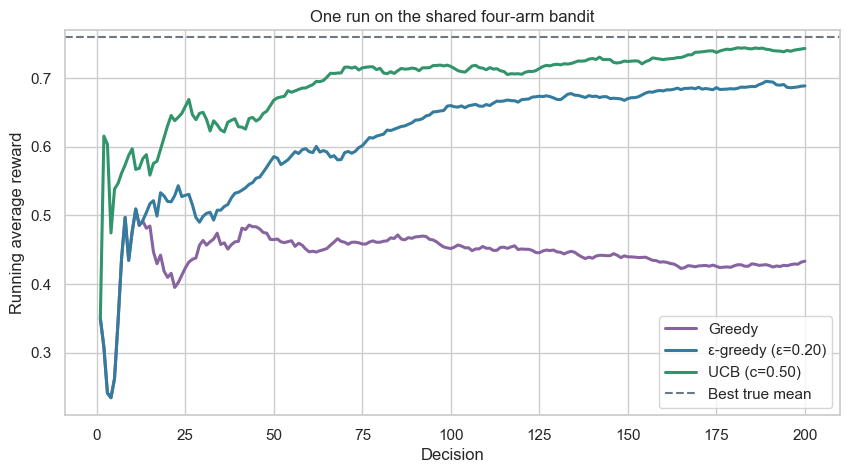

,final running average,share of decisions choosing true best arm
Greedy,0.433,0.000
ε-greedy (ε=0.20),0.689,0.715
UCB (c=0.50),0.743,0.890


In [5]:
policy_labels = {
    "greedy": "Greedy",
    "epsilon_greedy": "ε-greedy (ε=0.20)",
    "ucb": "UCB (c=0.50)",
}
policy_colors = {"greedy": "#8764a0", "epsilon_greedy": "#347b9e", "ucb": "#31946b"}

single_runs = {}
for policy in policy_labels:
    history, estimates, counts = run_bandit_policy(policy)
    single_runs[policy] = {"history": history, "estimates": estimates, "counts": counts}

best_mean = ARMS["mean_reward"].max()
fig, ax = plt.subplots(figsize=(10, 5))
for policy, result in single_runs.items():
    history = result["history"]
    ax.plot(history["step"], history["running_average_reward"],
            linewidth=2.2, color=policy_colors[policy], label=policy_labels[policy])

ax.axhline(best_mean, color="#6f7880", linestyle="--", label="Best true mean")
ax.set(xlabel="Decision", ylabel="Running average reward", title="One run on the shared four-arm bandit")
ax.legend()
plt.show()

summary = pd.DataFrame(
    {
        policy_labels[policy]: {
            "final running average": result["history"]["running_average_reward"].iloc[-1],
            "share of decisions choosing true best arm": result["history"]["selected_best_arm"].mean(),
        }
        for policy, result in single_runs.items()
    }
).T
summary.round(3)

## 4. Typical behavior across many runs

One trajectory can be lucky or unlucky. To compare policies fairly, we repeat the entire learning process with independent reward streams and average the resulting curves. We inspect two measures:

- **Cumulative average reward:** how much reward the policy has earned per decision so far.
- **Best-arm selection rate:** the percentage of simulations choosing the true best arm at each decision (Arm C in this fixed environment).

The light bands below are 95% pointwise **Monte Carlo confidence intervals**. They show how the estimated curves vary across repeated simulations of this fixed setup; they do not represent uncertainty about the fixed reward distributions.

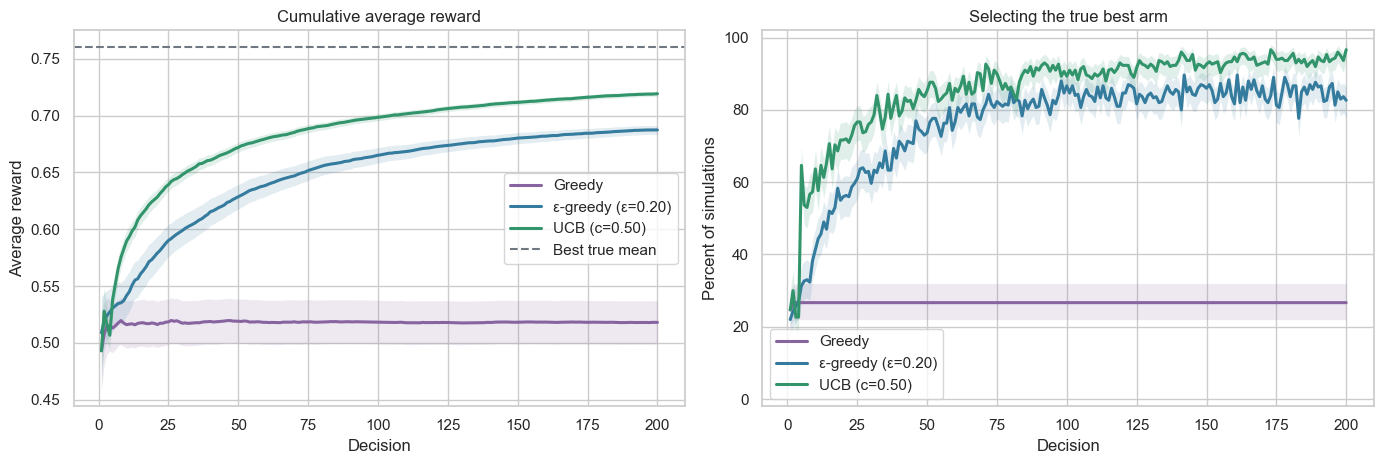

In [6]:
def mean_interval(curves, z=1.96):
    """Return a mean curve and a 95% pointwise Monte Carlo interval."""
    # This is the usual mean ± 1.96 × standard-error interval at each decision.
    mean = curves.mean(axis=0)
    standard_error = curves.std(axis=0, ddof=1) / np.sqrt(curves.shape[0])
    return {"mean": mean, "lower": mean - z * standard_error, "upper": mean + z * standard_error}


def wilson_interval(indicator_curves, z=1.96):
    """Return a robust 95% pointwise interval for a selection-rate curve."""
    # The 0/1 best-arm indicators can be near 0% or 100%, where Wilson intervals behave well.
    runs = indicator_curves.shape[0]
    rate = indicator_curves.mean(axis=0)
    denominator = 1 + z**2 / runs
    center = (rate + z**2 / (2 * runs)) / denominator
    half_width = z * np.sqrt(rate * (1 - rate) / runs + z**2 / (4 * runs**2)) / denominator
    return {"mean": rate, "lower": center - half_width, "upper": center + half_width}


def evaluate_policy(policy, runs=300, steps=200, epsilon=0.20, c=0.50):
    """Estimate two learning curves over independent replications of one bandit setup."""
    average_reward_curves = []
    best_arm_curves = []

    for run in range(runs):
        history, _, _ = run_bandit_policy(
            policy,
            steps=steps,
            epsilon=epsilon,
            c=c,
            environment_seed=10_000 + run,
            policy_seed=50_000 + run,
        )
        average_reward_curves.append(history["running_average_reward"].to_numpy())
        best_arm_curves.append(history["selected_best_arm"].to_numpy(dtype=float))

    return {
        "average_reward": mean_interval(np.asarray(average_reward_curves)),
        "best_arm_rate": wilson_interval(np.asarray(best_arm_curves)),
    }


averaged_runs = {policy: evaluate_policy(policy) for policy in policy_labels}
steps = np.arange(1, 201)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True)
for policy, curves in averaged_runs.items():
    reward = curves["average_reward"]
    best_arm_rate = curves["best_arm_rate"]
    axes[0].fill_between(steps, reward["lower"], reward["upper"], color=policy_colors[policy], alpha=0.14, linewidth=0)
    axes[0].plot(steps, reward["mean"], linewidth=2.2, color=policy_colors[policy], label=policy_labels[policy])
    axes[1].fill_between(steps, 100 * best_arm_rate["lower"], 100 * best_arm_rate["upper"], color=policy_colors[policy], alpha=0.14, linewidth=0)
    axes[1].plot(steps, 100 * best_arm_rate["mean"], linewidth=2.2, color=policy_colors[policy], label=policy_labels[policy])

axes[0].axhline(best_mean, color="#6f7880", linestyle="--", label="Best true mean")
axes[0].set(title="Cumulative average reward", xlabel="Decision", ylabel="Average reward")
axes[1].set(title="Selecting the true best arm", xlabel="Decision", ylabel="Percent of simulations", ylim=(-2, 102))
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

## Takeaways

- A greedy policy can commit to an arm after a lucky early reward and never learn about a better arm.
- $\epsilon$-greedy keeps sampling every arm, even after it has a strong estimate.
- UCB targets its exploration toward arms whose estimates remain uncertain.

The bandit has one state and immediate rewards. The next reinforcement-learning examples add a changing state and delayed consequences.

[← Return to Reinforcement learning](index.qmd)